# Problema 14 — Teoría de diagramas de fases

Cuaderno de **teoría y práctica**: primero se explica qué es un diagrama de fases, cómo se dibuja y qué relación tiene con el potencial efectivo $U_{eff}$; después se aplica a cuatro ejercicios y se comprueba además un paréntesis de Poisson.

| Parte | Contenido |
|-------|-----------|
| 1 | Espacio de fases y ecuaciones de Hamilton |
| 2 | Tres métodos para dibujar un diagrama de fases |
| 3 | Puntos fijos, estabilidad y separatrices |
| 4 | Relación entre $U_{eff}$ y el diagrama de fases |
| 5 | Ejercicio 25: potencial $-(x/a)^2U_0$ con paredes |
| 6 | Ejercicio 15: movimiento bajo $U=-k/r$ |
| 7 | Ejercicio 19: cuenta en un alambre helicoidal |
| 8 | Ejercicio 11: masa en caída libre |
| 9 | Ejercicio 12: paréntesis de Poisson (comprobación simbólica) |

## 1. Espacio de fases y ecuaciones de Hamilton

Para un sistema con $n$ grados de libertad, el **espacio de fases** es el espacio de dimensión $2n$ de coordenadas $(q_1,\dots,q_n,p_1,\dots,p_n)$. Un punto del espacio de fases describe el estado completo del sistema: dadas $(q,p)$ en un instante, el futuro y el pasado quedan determinados.

La evolución viene dada por las **ecuaciones de Hamilton**

$$\dot q_i=\frac{\partial H}{\partial p_i},\qquad \dot p_i=-\frac{\partial H}{\partial q_i}.$$

Esto define un **campo de velocidades** $(\dot q,\dot p)$ en el espacio de fases. Las **órbitas** (trayectorias de fases) son las curvas tangentes a ese campo. Hay propiedades que hacen sencillo dibujarlas:

- **Las órbitas no se cortan** (el estado determina la evolución), salvo en puntos fijos.
- Si $H$ no depende explícitamente del tiempo, **$H$ se conserva**: cada órbita está contenida en una **curva de nivel** $H(q,p)=E$.
- Sentido de recorrido: si $p>0$ (y $H=p^2/2m+U$), entonces $\dot q>0$ y $q$ aumenta. Las flechas apuntan a la derecha en el semiplano superior y a la izquierda en el inferior.
- **Teorema de Liouville**: el flujo conserva el área del espacio de fases. Por eso un punto fijo no puede ser un sumidero: solo hay centros y sillas.

En una dimensión, $H=\dfrac{p^2}{2m}+U(q)$ y las órbitas son

$$p(q)=\pm\sqrt{2m\,[E-U(q)]}.$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import sympy as sp

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})


def p_branch(U, q, E, m=1.0):
    # Rama p>=0 de p(q)=sqrt(2m(E-U(q))); NaN donde la región está prohibida (E<U).
    arg = 2 * m * (E - U(q))
    p = np.full(np.shape(q), np.nan, dtype=float)
    ok = arg >= 0
    p[ok] = np.sqrt(arg[ok])
    return p


def arrow(ax, x, y, color, frac=0.5):
    # Flecha en el punto de la curva (x, y) situado a la fracción 'frac' de sus puntos válidos.
    idx = np.where(~np.isnan(y))[0]
    if len(idx) < 3:
        return
    i = idx[int(frac * (len(idx) - 2))]
    ax.annotate("", xy=(x[i + 1], y[i + 1]), xytext=(x[i], y[i]),
                arrowprops=dict(arrowstyle="-|>", color=color, lw=1.5))

## 2. Tres métodos para dibujar un diagrama de fases

Dado un Hamiltoniano $H(q,p)$ hay tres formas, de más simple a más general. Se ilustran con el **péndulo simple** ($m=l=g=1$):

$$H(\theta,p)=\frac{p^2}{2}-\cos\theta .$$

**Método 1. Despejar $p(q)$.** Solo funciona si $H=p^2/2m+U(q)$. Se dibuja $\pm\sqrt{2m(E-U)}$ para varias $E$. Es el método que se usa en los ejercicios 25, 15 y 11.

**Método 2. Curvas de nivel de $H$.** Se calcula $H$ en una malla con `np.meshgrid` y se usa `plt.contour(Q, P, H, levels=...)`. No requiere despejar nada, así que sirve para cualquier $H(q,p)$.

**Método 3. Integrar las ecuaciones de Hamilton.** Se usa `solve_ivp` para varias condiciones iniciales y se dibuja $(q(t),p(t))$. Con `plt.streamplot` se ve el flujo completo. Es el único método válido si $H$ depende del tiempo o hay rozamiento.

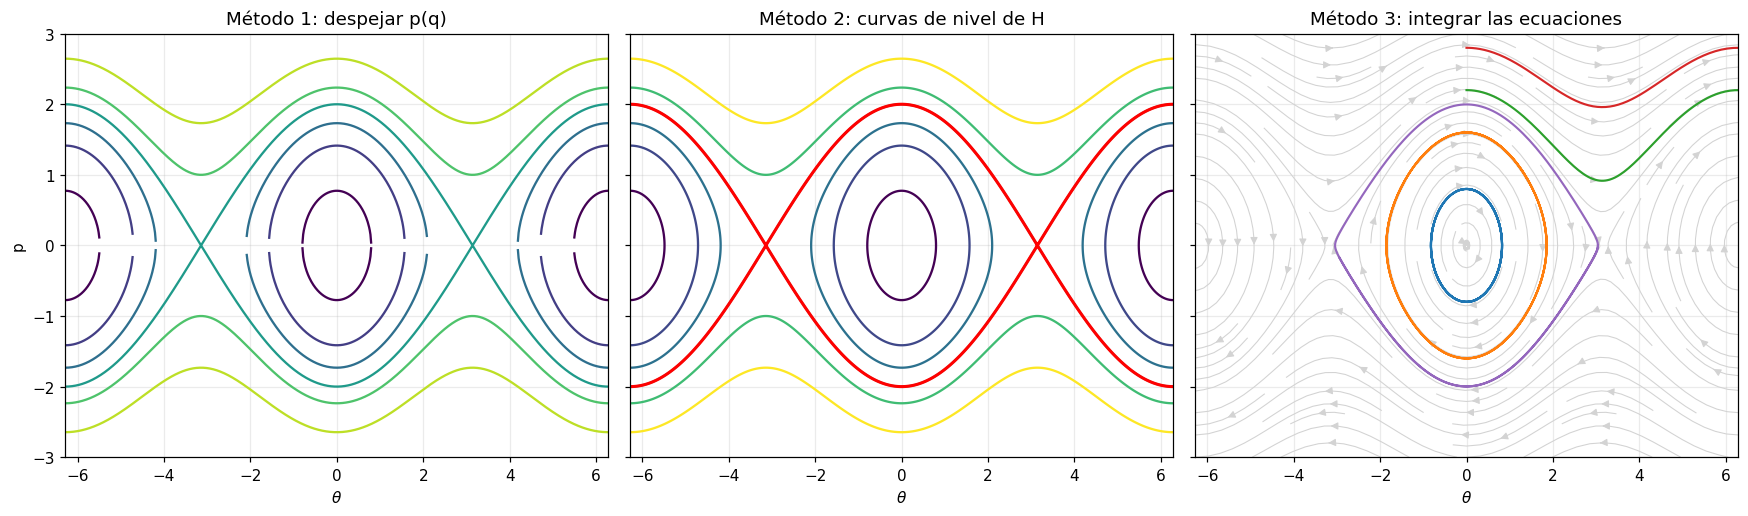

In [2]:
H = lambda q, p: 0.5 * p**2 - np.cos(q)
U = lambda q: -np.cos(q)
q = np.linspace(-2 * np.pi, 2 * np.pi, 800)

fig, axs = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)

# --- Método 1: p = ±sqrt(2(E-U)) ---
ax = axs[0]
for E, c in zip([-0.7, 0.0, 0.5, 1.0, 1.5, 2.5], plt.cm.viridis(np.linspace(0, .9, 6))):
    p = p_branch(U, q, E)
    ax.plot(q, p, color=c); ax.plot(q, -p, color=c)
ax.set_title("Método 1: despejar p(q)"); ax.set_xlabel(r"$\theta$"); ax.set_ylabel("p")

# --- Método 2: curvas de nivel ---
ax = axs[1]
Q, P = np.meshgrid(np.linspace(-2 * np.pi, 2 * np.pi, 600), np.linspace(-3, 3, 400))
ax.contour(Q, P, H(Q, P), levels=[-0.7, 0.0, 0.5, 1.0, 1.5, 2.5], cmap="viridis")
ax.contour(Q, P, H(Q, P), levels=[1.0], colors="r", linewidths=2)   # separatriz E = 1
ax.set_title("Método 2: curvas de nivel de H"); ax.set_xlabel(r"$\theta$")

# --- Método 3: integrar Hamilton + streamplot ---
ax = axs[2]
ax.streamplot(Q, P, P, -np.sin(Q), color="lightgray", density=1.3, linewidth=.7)
f = lambda t, y: [y[1], -np.sin(y[0])]          # qdot = p, pdot = -sin(q)
for y0 in [(0, 0.8), (0, 1.6), (0, 2.2), (0, 2.8), (np.pi - 0.1, 0.0)]:
    s = solve_ivp(f, [0, 25], y0, rtol=1e-9, atol=1e-11, max_step=.05)
    ax.plot(s.y[0], s.y[1], lw=1.4)
ax.set_title("Método 3: integrar las ecuaciones"); ax.set_xlabel(r"$\theta$")

for ax in axs: ax.set_xlim(-2 * np.pi, 2 * np.pi); ax.set_ylim(-3, 3)
plt.tight_layout(); plt.show()

## 3. Puntos fijos, estabilidad y separatrices

Un **punto fijo** (equilibrio) cumple $\dot q=\dot p=0$, es decir, $\partial H/\partial q=\partial H/\partial p=0$. Se clasifica linealizando. Con el Jacobiano de $(\dot q,\dot p)=(H_p,-H_q)$ se obtiene

$$\det J = H_{qq}H_{pp}-H_{qp}^2 .$$

- $\det J>0$: **centro** (estable). Las órbitas cercanas son cerradas. Corresponde a un **mínimo** de $H$.
- $\det J<0$: **silla** (inestable). Las órbitas cercanas se alejan siguiendo hipérbolas. Corresponde a un **máximo de $U_{eff}$**.

Una **separatriz** es la órbita que pasa por la silla (o tiende a ella). Separa tipos de movimiento distintos, por ejemplo oscilación y rotación en el péndulo, o ligado y no ligado en Kepler.

In [3]:
q_, p_ = sp.symbols("q p", real=True)

def puntos_fijos(Hs, guesses):
    qd, pd = sp.diff(Hs, p_), -sp.diff(Hs, q_)
    J = sp.Matrix([qd, pd]).jacobian([q_, p_])
    for g in guesses:
        sol = sp.nsolve([qd, pd], [q_, p_], g)
        Jp = J.subs({q_: sol[0], p_: sol[1]})
        det = float(sp.det(Jp).evalf())
        tipo = "centro (estable)" if det > 0 else "silla (inestable)"
        print(f"(q, p) = ({float(sol[0]):+.3f}, {float(sol[1]):+.3f})  det J = {det:+.2f}  ->  {tipo}")

puntos_fijos(p_**2 / 2 - sp.cos(q_), [(0.1, 0.1), (3.0, 0.1)])

(q, p) = (-0.000, +0.000)  det J = +1.00  ->  centro (estable)
(q, p) = (+3.142, +0.000)  det J = -1.00  ->  silla (inestable)


## 4. Relación entre $U_{eff}$ y el diagrama de fases

Cuando $H=\dfrac{p^2}{2m}+U_{eff}(q)$, el diagrama de fases es el **potencial efectivo visto "de lado"**, porque $E=\dfrac{p^2}{2m}+U_{eff}(q)$ implica

$$p(q)=\pm\sqrt{2m\,[E-U_{eff}(q)]}.$$

| En $U_{eff}(q)$ | En el diagrama de fases $(q,p)$ |
|-----------------|--------------------------------|
| Altura $E-U_{eff}(q)$ | $p^2/2m$ (la energía cinética es la distancia entre la recta $E$ y la curva $U_{eff}$) |
| Cortes $E=U_{eff}(q)$ | **Puntos de retorno**, donde la órbita corta el eje $p=0$ |
| Región con $U_{eff}>E$ | Región prohibida: no hay órbita |
| Mínimo de $U_{eff}$ | **Centro**: órbitas cerradas alrededor (movimiento ligado) |
| Máximo de $U_{eff}$ | **Silla**: separatriz y equilibrio inestable |
| $E$ por debajo del máximo | Órbita confinada en un pozo |
| $E$ por encima del máximo | Órbita que pasa de un lado a otro, o abierta |

**Potencial efectivo.** Si hay una coordenada cíclica $\varphi$, su momento $p_\varphi$ se conserva y el problema se reduce a una dimensión con un potencial efectivo. Por ejemplo, en un campo central $U_{eff}(r)=\dfrac{L^2}{2mr^2}+U(r)$. Si no hay coordenadas cíclicas, $U_{eff}=U$.

La función siguiente dibuja ambos paneles a la vez para cualquier $U$. La demostración usa un pozo doble $U=q^4/4-q^2/2$.

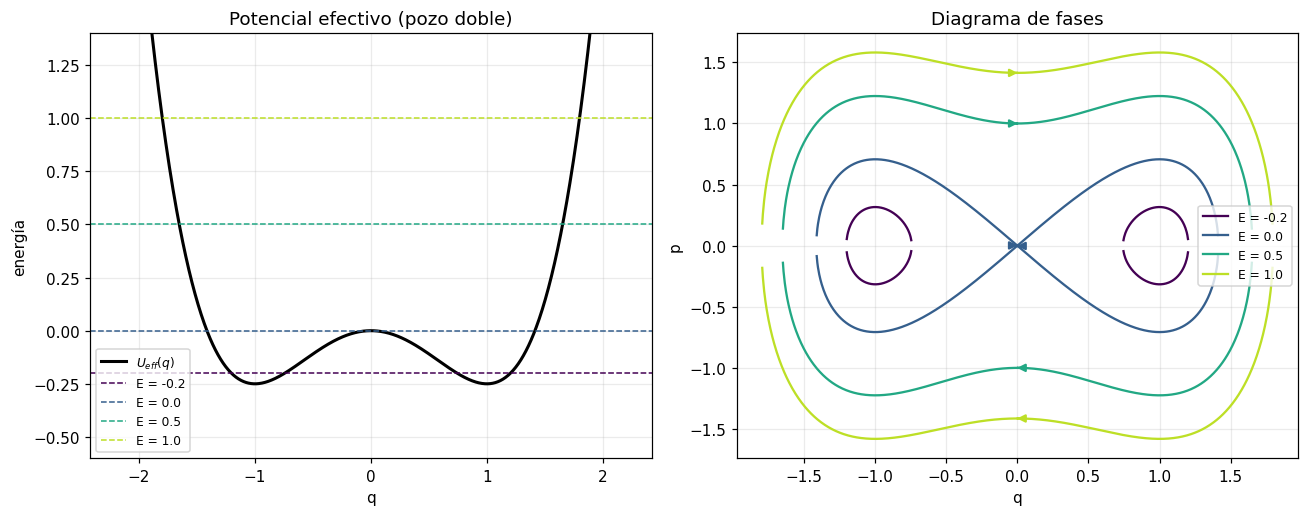

In [4]:
def potencial_y_fases(U, qgrid, energias, m=1.0, titulo="", ylimU=None):
    # Dibuja U(q) con las rectas E y el diagrama de fases (q, p) para cada E.
    cols = plt.cm.viridis(np.linspace(0, .9, len(energias)))
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.8))
    a1.plot(qgrid, U(qgrid), "k", lw=2, label=r"$U_{eff}(q)$")
    for E, c in zip(energias, cols):
        a1.axhline(E, color=c, ls="--", lw=1, label=f"E = {E}")
        p = p_branch(U, qgrid, E, m)
        a2.plot(qgrid, p, color=c, label=f"E = {E}"); a2.plot(qgrid, -p, color=c)
        arrow(a2, qgrid, p, c); arrow(a2, qgrid[::-1], -p[::-1], c)
    if ylimU: a1.set_ylim(*ylimU)
    a1.set_xlabel("q"); a1.set_ylabel("energía"); a1.set_title("Potencial efectivo " + titulo); a1.legend(fontsize=8)
    a2.set_xlabel("q"); a2.set_ylabel("p"); a2.set_title("Diagrama de fases"); a2.legend(fontsize=8)
    plt.tight_layout(); plt.show()

potencial_y_fases(lambda q: q**4 / 4 - q**2 / 2, np.linspace(-2.2, 2.2, 1000),
                  [-0.2, 0.0, 0.5, 1.0], titulo="(pozo doble)", ylimU=(-0.6, 1.4))

## 5. Ejercicio 25 — Potencial $U(x)=-(x/a)^2U_0$ con paredes

Una partícula de masa $m$ se mueve en el eje $x$ con

$$U(x)=\begin{cases}-\left(\dfrac{x}{a}\right)^2U_0 & |x|\le a\\[2mm] +\infty & |x|>a\end{cases}$$

**Hamiltoniano** (en $|x|\le a$): $H=\dfrac{p^2}{2m}-U_0\dfrac{x^2}{a^2}$. Como $T$ es cuadrática en $\dot x$ y $U$ no depende de $t$, $H=E$ y la energía se conserva. En una dimensión $U_{eff}=U$.

**Equilibrio.** $U'(x)=0$ en $x=0$, que es un **máximo**, es decir, un equilibrio **inestable** (silla).

**Ecuaciones de Hamilton:** $\dot x=p/m,\ \dot p=2U_0x/a^2$, o sea $\ddot x=\Omega^2x$ con $\Omega=\sqrt{2U_0/(ma^2)}$.

**Puntos de retorno:** $p=0\Rightarrow x^2=-Ea^2/U_0$.

- $E>0$: no hay raíz real, así que no hay retornos interiores. La partícula cruza de pared a pared y solo gira en $x=\pm a$ (las paredes invierten $p\to-p$).
- $E<0$: $x_t=\pm a\sqrt{|E|/U_0}$. La partícula queda en un solo lado (no puede pasar el máximo) y oscila entre $x_t$ y la pared.
- $E=0$: separatriz $p=\pm\sqrt{2mU_0}\,x/a$. Se acerca asintóticamente a $x=0$ sin llegar.

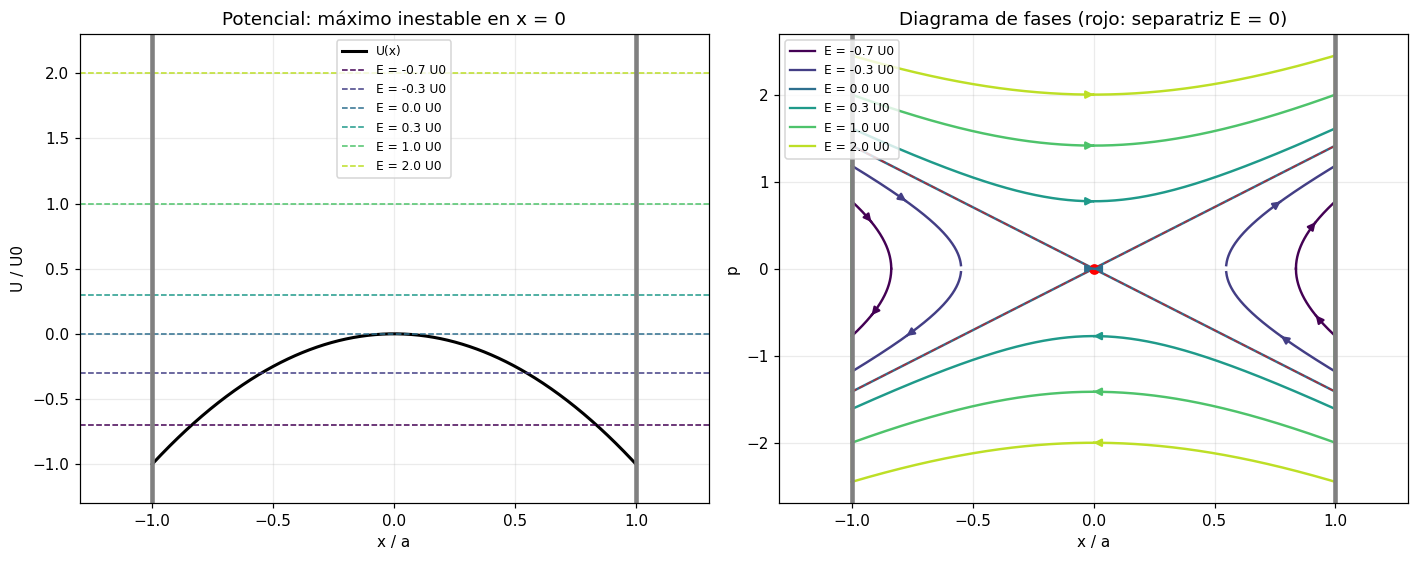

In [5]:
m, U0, a = 1.0, 1.0, 1.0
U25 = lambda x: -U0 * (x / a) ** 2
energias = [-0.7, -0.3, 0.0, 0.3, 1.0, 2.0]
cols = plt.cm.viridis(np.linspace(0, .9, len(energias)))

fig, (axU, axF) = plt.subplots(1, 2, figsize=(13, 5.2))
x = np.linspace(-a, a, 600)
axU.plot(x, U25(x), "k", lw=2, label="U(x)")
for E, c in zip(energias, cols):
    axU.axhline(E * U0, color=c, ls="--", lw=1, label=f"E = {E} U0")
axU.axvline(-a, color="gray", lw=3); axU.axvline(a, color="gray", lw=3)
axU.set_xlim(-1.3, 1.3); axU.set_ylim(-1.3, 2.3)
axU.set_xlabel("x / a"); axU.set_ylabel("U / U0"); axU.set_title("Potencial: máximo inestable en x = 0"); axU.legend(fontsize=8)

for E, c in zip(energias, cols):
    if E >= 0:
        regiones = [np.linspace(-a, a, 800)]
    else:
        xt = a * np.sqrt(abs(E) / U0)
        regiones = [np.linspace(xt, a, 600), np.linspace(-a, -xt, 600)]
    for xr in regiones:
        p = p_branch(U25, xr, E * U0, m)
        axF.plot(xr, p, color=c, lw=1.6); axF.plot(xr, -p, color=c, lw=1.6)
        arrow(axF, xr, p, c); arrow(axF, xr[::-1], -p[::-1], c)
        for xw in (-a, a):                                   # rebote en la pared: p -> -p
            if min(abs(xr[0] - xw), abs(xr[-1] - xw)) < 1e-9:
                pw = p_branch(U25, np.array([xw]), E * U0, m)[0]
                axF.plot([xw, xw], [-pw, pw], color=c, lw=1.6)
    axF.plot([], [], color=c, label=f"E = {E} U0")
xs = np.array([-a, a])
axF.plot(xs, np.sqrt(2 * m * U0) * xs / a, "r--", lw=1, alpha=.6)
axF.plot(xs, -np.sqrt(2 * m * U0) * xs / a, "r--", lw=1, alpha=.6)
axF.plot(0, 0, "ro")
axF.axvline(-a, color="gray", lw=3); axF.axvline(a, color="gray", lw=3)
axF.set_xlim(-1.3, 1.3); axF.set_xlabel("x / a"); axF.set_ylabel("p")
axF.set_title("Diagrama de fases (rojo: separatriz E = 0)"); axF.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

## 6. Ejercicio 15 — Movimiento bajo $U(r)=-k/r$

En coordenadas esféricas,

$$L=\tfrac12m\left(\dot r^2+r^2\dot\theta^2+r^2\sin^2\theta\,\dot\varphi^2\right)+\frac kr,\qquad H=\frac{p_r^2}{2m}+\frac{p_\theta^2}{2mr^2}+\frac{p_\varphi^2}{2mr^2\sin^2\theta}-\frac kr .$$

$\varphi$ es **cíclica**, así que $p_\varphi$ se conserva. $H$ no depende de $t$ y $T$ es cuadrática en las velocidades, luego $H=E$ se conserva. Con $\varphi=0$ (movimiento plano) $p_\varphi=0$ y $\dot p_\theta=0$, es decir, $p_\theta=L$ es constante, y

$$E=\frac{p_r^2}{2m}+U_{eff}(r),\qquad U_{eff}(r)=\frac{L^2}{2mr^2}-\frac kr .$$

**Puntos de retorno** ($p_r=0$):

$$\frac1{r^{(\pm)}}=\frac{km}{L^2}\left(1\pm\sqrt{1+\frac{2L^2E}{mk^2}}\right).$$

El mínimo de $U_{eff}$ está en $r_0=L^2/mk$ con $U_{eff}(r_0)=-mk^2/2L^2$, que es la órbita circular. Se distinguen tres casos:

- $U_{eff}(r_0)<E<0$: movimiento acotado (elipse).
- $E=0$: parábola, no acotado.
- $E>0$: hipérbola, no acotado. Solo hay $r^{(+)}$ (pericentro) y la órbita escapa a infinito.

En $(\theta,p_\theta)$ las órbitas son **rectas horizontales** porque $p_\theta$ es constante. $\theta$ crece monótonamente ($\dot\theta=L/mr^2>0$).

**Ecuación radial (apartado i).** De $\dot p_r=L^2/(mr^3)-k/r^2$ se obtiene $m\ddot r=L^2/(mr^3)-k/r^2$. Es la ecuación de Newton con la fuerza centrífuga (repulsiva) y la fuerza atractiva $-k/r^2$. Para dos planetas, $k=G\,m_1m_2$ y $m$ pasa a ser la masa reducida $\mu=m_1m_2/(m_1+m_2)$.

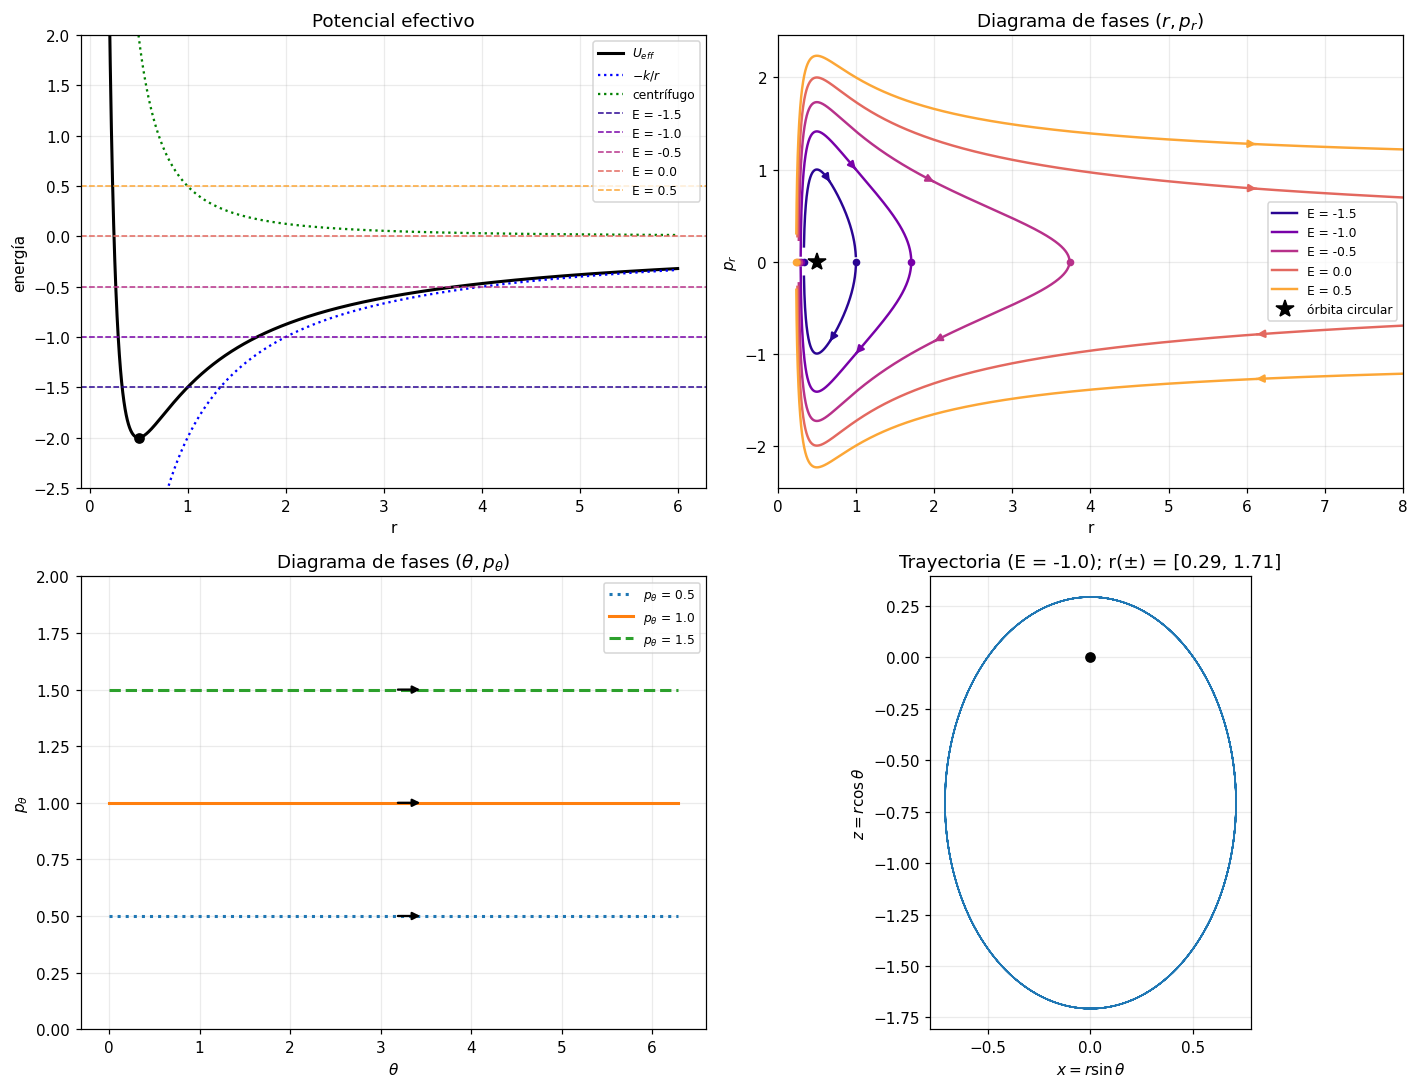

Variación máxima de E a lo largo de la integración: 4.377829876389683e-09


In [6]:
m, k, L = 1.0, 2.0, 1.0                    # L = p_theta
r0, Umin = L**2 / (m * k), -m * k**2 / (2 * L**2)
Ueff = lambda r, L=L: L**2 / (2 * m * r**2) - k / r

def r_retorno(E):
    disc = 1 + 2 * L**2 * E / (m * k**2)
    if disc < 0: return None
    s = np.sqrt(disc)
    inv_p, inv_m = (k * m / L**2) * (1 + s), (k * m / L**2) * (1 - s)
    return 1 / inv_p, (1 / inv_m if inv_m > 1e-12 else np.inf)

energias = [-1.5, -1.0, -0.5, 0.0, 0.5]
cols = plt.cm.plasma(np.linspace(.05, .8, len(energias)))
fig, axs = plt.subplots(2, 2, figsize=(13, 10))
axU, axR, axT, axX = axs.ravel()

r = np.linspace(0.2, 6, 2000)
axU.plot(r, Ueff(r), "k", lw=2, label=r"$U_{eff}$")
axU.plot(r, -k / r, "b:", label=r"$-k/r$"); axU.plot(r, L**2 / (2 * m * r**2), "g:", label="centrífugo")
for E, c in zip(energias, cols): axU.axhline(E, color=c, ls="--", lw=1, label=f"E = {E}")
axU.plot(r0, Umin, "ko"); axU.set_ylim(-2.5, 2); axU.set_xlabel("r"); axU.set_ylabel("energía")
axU.set_title("Potencial efectivo"); axU.legend(fontsize=8)

for E, c in zip(energias, cols):
    rr = np.linspace(0.05, 12, 6000)
    p = p_branch(Ueff, rr, E, m)
    axR.plot(rr, p, color=c, lw=1.6, label=f"E = {E}"); axR.plot(rr, -p, color=c, lw=1.6)
    arrow(axR, rr, p, c); arrow(axR, rr[::-1], -p[::-1], c)
    rt = r_retorno(E)
    if rt:
        pts = [rt[0]] + ([rt[1]] if np.isfinite(rt[1]) else [])
        axR.plot(pts, np.zeros(len(pts)), "o", color=c, ms=4)
axR.plot(r0, 0, "k*", ms=12, label="órbita circular")
axR.set_xlim(0, 8); axR.set_xlabel("r"); axR.set_ylabel(r"$p_r$"); axR.set_title(r"Diagrama de fases $(r,p_r)$"); axR.legend(fontsize=8)

for Lv, ls in [(0.5, ":"), (1.0, "-"), (1.5, "--")]:
    th = np.linspace(0, 2 * np.pi, 200)
    axT.plot(th, np.full_like(th, Lv), ls, lw=2, label=fr"$p_\theta$ = {Lv}")
    axT.annotate("", xy=(th[110], Lv), xytext=(th[100], Lv), arrowprops=dict(arrowstyle="-|>", color="k", lw=1.5))
axT.set_ylim(0, 2); axT.set_xlabel(r"$\theta$"); axT.set_ylabel(r"$p_\theta$")
axT.set_title(r"Diagrama de fases $(\theta,p_\theta)$"); axT.legend(fontsize=8)

def hamilton(t, y):
    r_, th, pr, pth = y
    return [pr / m, pth / (m * r_**2), pth**2 / (m * r_**3) - k / r_**2, 0.0]
E = -1.0; rp, ra = r_retorno(E)
s = solve_ivp(hamilton, [0, 25], [rp, 0, 0, L], rtol=1e-10, atol=1e-12, dense_output=True)
rt_, tht, prt, _ = s.sol(np.linspace(0, 25, 5000))
axX.plot(rt_ * np.sin(tht), rt_ * np.cos(tht), lw=1); axX.plot(0, 0, "ko"); axX.set_aspect("equal")
axX.set_xlabel(r"$x=r\sin\theta$"); axX.set_ylabel(r"$z=r\cos\theta$"); axX.set_title(f"Trayectoria (E = {E}); r(±) = [{rp:.2f}, {ra:.2f}]")
plt.tight_layout(); plt.show()
print("Variación máxima de E a lo largo de la integración:", np.ptp(prt**2 / (2 * m) + Ueff(rt_)))

## 7. Ejercicio 19 — Cuenta en un alambre helicoidal

Alambre $x=a\cos\theta,\ y=a\sin\theta,\ z=b\theta$ (eje $z$ vertical hacia arriba) y una cuenta de masa $m$ bajo la gravedad. La velocidad cumple $v^2=(a^2+b^2)\dot\theta^2$, de modo que, con $M\equiv m(a^2+b^2)$,

$$L=\tfrac12M\dot\theta^2-mgb\,\theta,\qquad p=M\dot\theta,\qquad H=\frac{p^2}{2M}+mgb\,\theta .$$

**Ecuaciones de Hamilton:** $\dot\theta=p/M,\ \dot p=-mgb$. Por tanto

$$\ddot\theta=-\frac{gb}{a^2+b^2}\equiv c<0 .$$

**Potencial efectivo.** Con una sola coordenada, $U_{eff}=U=mgb\,\theta$ es una **recta**: no tiene máximos ni mínimos, así que **no hay puntos de equilibrio**. Las órbitas son **parábolas** $p^2=2M(E-mgb\,\theta)$ abiertas hacia $\theta\to-\infty$.

**Condiciones iniciales** $\theta(0)=0,\ \dot\theta(0)=\dot\theta^{(0)}>0$. La cuenta sube por la hélice frenándose a ritmo constante hasta

$$\theta_{max}=\frac{(\dot\theta^{(0)})^2}{2|c|},\qquad t^*=\frac{\dot\theta^{(0)}}{|c|}.$$

En ese punto $p=0$ y se invierte el movimiento. Después **baja indefinidamente** ($\dot\theta<0$ y creciente en módulo), sin volver a oscilar.

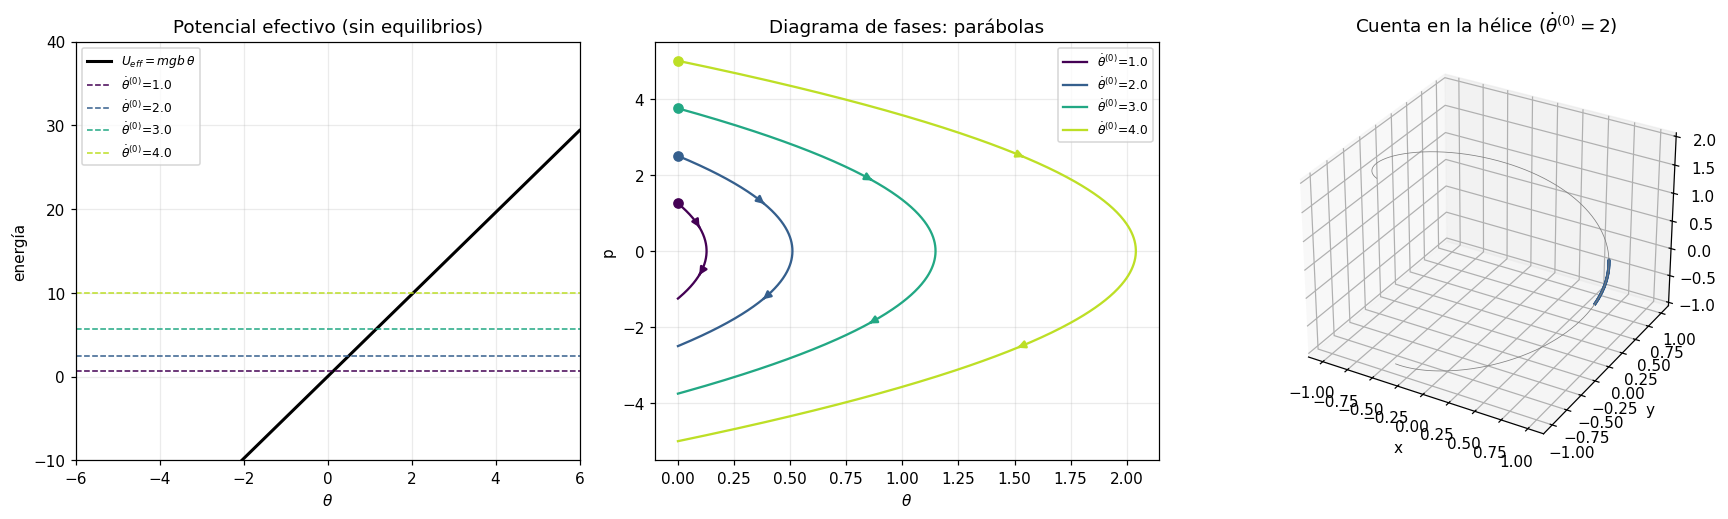

c = -3.9200 rad/s²   |   theta_max para thd0 = [1.0, 2.0, 3.0, 4.0]: [0.128, 0.51, 1.148, 2.041]


In [7]:
m, g, a, b = 1.0, 9.8, 1.0, 0.5
M = m * (a**2 + b**2); c = -g * b / (a**2 + b**2)
Uh = lambda th: m * g * b * th
thd0s = [1.0, 2.0, 3.0, 4.0]
cols = plt.cm.viridis(np.linspace(0, .9, len(thd0s)))

fig = plt.figure(figsize=(16, 4.8))
ax1, ax2, ax3 = fig.add_subplot(131), fig.add_subplot(132), fig.add_subplot(133, projection="3d")
th = np.linspace(-6, 6, 400)
ax1.plot(th, Uh(th), "k", lw=2, label=r"$U_{eff}=mgb\,\theta$")
for thd0, col in zip(thd0s, cols):
    E = 0.5 * M * thd0**2
    ax1.axhline(E, color=col, ls="--", lw=1, label=fr"$\dot\theta^{{(0)}}$={thd0}")
    tstar = thd0 / abs(c); t = np.linspace(0, 2 * tstar, 400)
    thv, pv = thd0 * t + 0.5 * c * t**2, M * (thd0 + c * t)          # solución analítica
    ax2.plot(thv, pv, color=col, label=fr"$\dot\theta^{{(0)}}$={thd0}")
    k_ = len(t) // 4; ax2.annotate("", xy=(thv[k_ + 1], pv[k_ + 1]), xytext=(thv[k_], pv[k_]), arrowprops=dict(arrowstyle="-|>", color=col, lw=1.6))
    k_ = 3 * len(t) // 4; ax2.annotate("", xy=(thv[k_ + 1], pv[k_ + 1]), xytext=(thv[k_], pv[k_]), arrowprops=dict(arrowstyle="-|>", color=col, lw=1.6))
    ax2.plot(thv[0], pv[0], "o", color=col)
    if thd0 == 2.0:
        ax3.plot(a * np.cos(thv), a * np.sin(thv), b * thv, color=col, lw=2, label="cuenta")
        thh = np.linspace(-2, 4, 600); ax3.plot(a * np.cos(thh), a * np.sin(thh), b * thh, "gray", lw=.5)
ax1.set_ylim(-10, 40); ax1.set_xlim(-6, 6); ax1.set_xlabel(r"$\theta$"); ax1.set_ylabel("energía"); ax1.set_title("Potencial efectivo (sin equilibrios)"); ax1.legend(fontsize=8)
ax2.set_xlabel(r"$\theta$"); ax2.set_ylabel("p"); ax2.set_title("Diagrama de fases: parábolas"); ax2.legend(fontsize=8)
ax3.set_title(r"Cuenta en la hélice ($\dot\theta^{(0)}=2$)"); ax3.set_xlabel("x"); ax3.set_ylabel("y"); ax3.set_zlabel("z")
plt.tight_layout(); plt.show()
print(f"c = {c:.4f} rad/s²   |   theta_max para thd0 = {thd0s}: {[round(t**2 / (2 * abs(c)), 3) for t in thd0s]}")

## 8. Ejercicio 11 — Masa en caída libre

Con $x$ medida **hacia abajo**, $T=\tfrac12m\dot x^2$ y $U=-mgx$, de modo que

$$H=\frac{p^2}{2m}-mgx,\qquad \dot x=\frac pm,\qquad \dot p=mg .$$

La solución es inmediata: $p(t)=p_0+mgt$ y $x(t)=x_0+\dfrac{p_0}{m}t+\dfrac12gt^2$.

**Potencial efectivo:** $U_{eff}=U=-mgx$, una recta con pendiente $-mg$ (sin equilibrios). Eliminando $t$, las órbitas son **parábolas**

$$x=\frac{p^2}{2m^2g}-\frac{E}{mg},\qquad E=\frac{p_0^2}{2m}-mgx_0 .$$

Como $\dot p=mg>0$, **$p$ siempre crece**: el flujo apunta hacia arriba en el diagrama $(x,p)$, y $x$ aumenta si $p>0$ y disminuye si $p<0$.

| Caso | $(x_0,p_0)$ | $E$ | Comportamiento |
|------|-------------|-----|----------------|
| (a) | $(0,0)$ | $0$ | Parte del vértice de la parábola $x=p^2/2m^2g$ |
| (b) | $(X,0)$ | $-mgX$ | Parte del vértice de una parábola desplazada hacia $x=X$ |
| (c) | $(X,P)$ | $P^2/2m-mgX$ | Parte con $p>0$, cae más rápido |
| (d) | $(0,P)$ | $P^2/2m$ | Igual que (c), con $x_0=0$ |

Si $P<0$ (lanzamiento hacia arriba) la partícula sube, $p$ cruza $0$ en el vértice y luego baja.

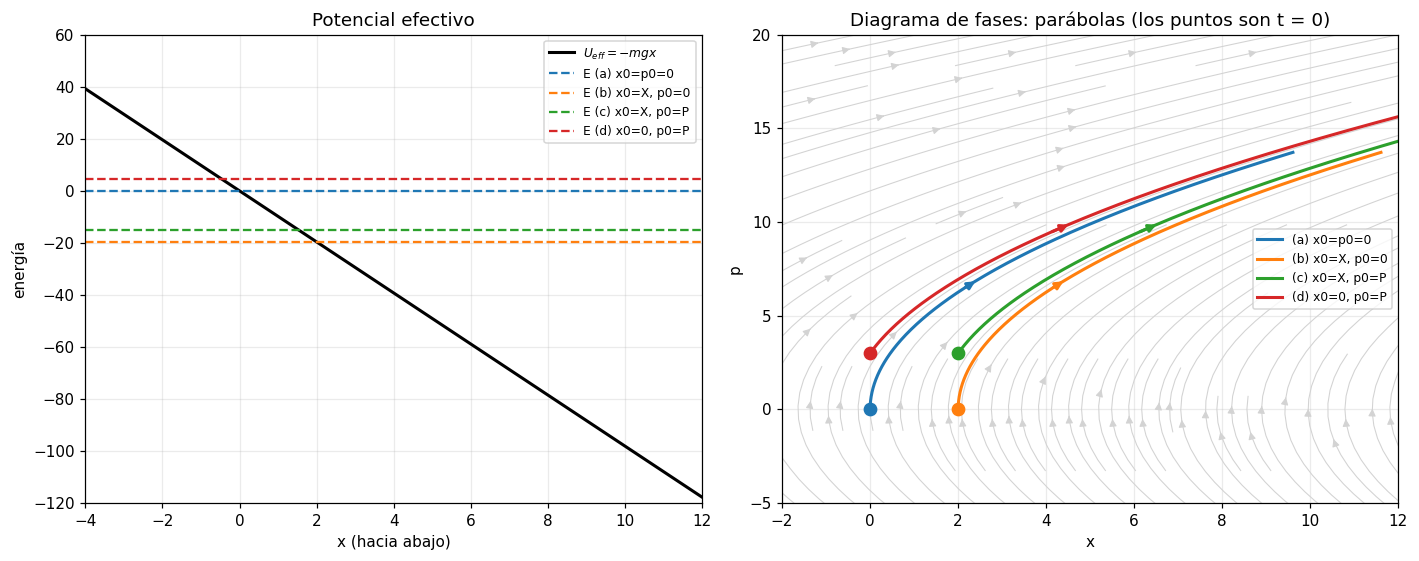

In [8]:
m, g, X, P = 1.0, 9.8, 2.0, 3.0
casos = {"(a) x0=p0=0": (0, 0), "(b) x0=X, p0=0": (X, 0), "(c) x0=X, p0=P": (X, P), "(d) x0=0, p0=P": (0, P)}
cols = ["C0", "C1", "C2", "C3"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5.2))

x = np.linspace(-4, 12, 400)
a1.plot(x, -m * g * x, "k", lw=2, label=r"$U_{eff}=-mgx$")
for (nom, (x0, p0)), col in zip(casos.items(), cols):
    a1.axhline(p0**2 / (2 * m) - m * g * x0, color=col, ls="--", label=f"E {nom}")
a1.set_xlim(-4, 12); a1.set_ylim(-120, 60); a1.set_xlabel("x (hacia abajo)"); a1.set_ylabel("energía"); a1.set_title("Potencial efectivo"); a1.legend(fontsize=8)

Xg, Pg = np.meshgrid(np.linspace(-2, 12, 40), np.linspace(-10, 20, 40))
a2.streamplot(Xg, Pg, Pg / m, m * g * np.ones_like(Pg), color="lightgray", density=1.4, linewidth=.7)
for (nom, (x0, p0)), col in zip(casos.items(), cols):
    t = np.linspace(0, 1.4, 300)
    xv, pv = x0 + p0 * t / m + 0.5 * g * t**2, p0 + m * g * t
    a2.plot(xv, pv, color=col, lw=2, label=nom); a2.plot(x0, p0, "o", color=col, ms=8)
    a2.annotate("", xy=(xv[151], pv[151]), xytext=(xv[140], pv[140]), arrowprops=dict(arrowstyle="-|>", color=col, lw=2))
a2.set_xlim(-2, 12); a2.set_ylim(-5, 20); a2.set_xlabel("x"); a2.set_ylabel("p"); a2.set_title("Diagrama de fases: parábolas (los puntos son t = 0)"); a2.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 9. Ejercicio 12 — Paréntesis de Poisson $[A,H]$

Con $L=\tfrac12\left(\dot x^2/x+\dot y^2/y\right)$ los momentos son $p_x=\dot x/x,\ p_y=\dot y/y$ y

$$H=\tfrac12\left(x\,p_x^2+y\,p_y^2\right),\qquad A=x\dot y-y\dot x=xy\,(p_y-p_x).$$

El paréntesis de Poisson es $[A,H]=\sum_i\left(\dfrac{\partial A}{\partial q_i}\dfrac{\partial H}{\partial p_i}-\dfrac{\partial A}{\partial p_i}\dfrac{\partial H}{\partial q_i}\right)$, y $\dot A=[A,H]$ si $A$ no depende explícitamente de $t$. Se comprueba simbólicamente.

In [9]:
x, y, px, py = sp.symbols("x y p_x p_y", positive=True)
Hs = sp.Rational(1, 2) * (x * px**2 + y * py**2)
As = x * y * (py - px)

def poisson(f, g_, qs, ps):
    return sum(sp.diff(f, q_i) * sp.diff(g_, p_i) - sp.diff(f, p_i) * sp.diff(g_, q_i) for q_i, p_i in zip(qs, ps))

AH = sp.factor(sp.simplify(poisson(As, Hs, [x, y], [px, py])))
print("[A, H] =", AH)
xd, yd = sp.symbols("xdot ydot", positive=True)
print("En velocidades:", sp.simplify(AH.subs({px: xd / x, py: yd / y})))

[A, H] = -x*y*(p_x - p_y)*(p_x + p_y)/2
En velocidades: x*ydot**2/(2*y) - xdot**2*y/(2*x)


**Resultado:**

$$[A,H]=\tfrac12\,xy\,(p_y^2-p_x^2)=\tfrac12\,xy\left(\frac{\dot y^2}{y^2}-\frac{\dot x^2}{x^2}\right)=\tfrac12\left(\frac{x\,\dot y^2}{y}-\frac{y\,\dot x^2}{x}\right).$$

Como $[A,H]\neq0$, $A$ **no es una cantidad conservada**.

---

## Resumen: cómo dibujar un diagrama de fases cuando ya sabes qué hacer

1. Escribe $H(q,p)$ y comprueba si se conserva ($H=E$).
2. Si hay coordenadas cíclicas, sustituye sus momentos por constantes y construye $U_{eff}$.
3. Dibuja $U_{eff}$ y marca mínimos (centros) y máximos (sillas).
4. Elige varias energías $E$ (por debajo, igual y por encima de los máximos).
5. Dibuja $p=\pm\sqrt{2m(E-U_{eff})}$ (o `contour` de $H$, o integra Hamilton).
6. Añade las flechas: hacia la derecha si $p>0$ y hacia la izquierda si $p<0$.
7. Marca los puntos de retorno ($p=0$), la separatriz y la región prohibida.